# FIFA World Cup 2026 regression project

HIT140 Assessment 3. Retain the teammate's original two eight-predictor OLS models,
fixed test partitions and coefficient tables. Add training-only five-fold validation,
reproducible report figures, a training-mean benchmark, a small scaled-Ridge
comparison and residual diagnostics. Ridge tries alpha 1, 10 and 100 using the same
training folds; the lowest mean validation RMSE selects its penalty per task.

The mean benchmark is in the supplied Week 9 exercises. Ridge is one additional
regularised linear-regression method beyond the supplied lecture notes.
CV values used to select Ridge are selection scores. The original test outcomes
were inspected in earlier drafts; these are not fresh blind tests. Random splits
do not establish future-tournament forecasting performance. Source limitations
remain in FIFA_Data_Source_Checks.md.


## Read the supplied CSV files

Run from this folder. The five supplied CSV files are included unchanged. Identifiers are keys, not regression inputs.


In [1]:
import pandas as pd

matches = pd.read_csv("matches_detailed.csv")
features = pd.read_csv("match_prediction_features_X.csv")
targets = pd.read_csv("match_prediction_targets_y.csv")

print("Total Matches:", matches.shape)
print("Features Dataset:", features.shape)
print("Targets Dataset:", targets.shape)

display(matches.head())


Total Matches: (104, 23)
Features Dataset: (104, 60)
Targets Dataset: (104, 7)


,match_id,date,kickoff_time_utc,stage_name,stadium_name,city,country,home_team_name,home_fifa_code,away_team_name,away_fifa_code,home_score,away_score,home_penalty_score,away_penalty_score,status,result_type,home_xg,away_xg,home_goalkeeper,away_goalkeeper,player_of_the_match_name,referee_name
0,1,2026-06-11,19:00,Group Stage,Mexico City Stadium (Estadio Azteca),Mexico City,MEX,Mexico,MEX,South Africa,RSA,2,0,NaN,NaN,Completed,Regular,1.84,0.52,José Raúl Rangel,Ronwen Hayden Williams,Julián Andrés Quinones,Daniele Orsato
1,2,2026-06-11,23:00,Group Stage,Guadalajara Stadium (Estadio Akron),Zapopan,MEX,South Korea,KOR,Czechia,CZE,2,1,NaN,NaN,Completed,Regular,1.45,1.12,Seunggyu Kim,Mat ě j Kovar,Inbeom Hwang,César Arturo Ramos
2,3,2026-06-12,19:00,Group Stage,Toronto Stadium (BMO Field),Toronto,CAN,Canada,CAN,Bosnia and Herzegovina,BIH,1,1,NaN,NaN,Completed,Regular,1.35,0.98,Maxime Crepeau,Nikola Vasilj,Ismaël Kenneth Jordan Kone,Mustapha Ghorbal
3,4,2026-06-12,23:00,Group Stage,Los Angeles Stadium (SoFi Stadium),Inglewood,USA,USA,USA,Paraguay,PAR,4,1,NaN,NaN,Completed,Regular,2.76,0.88,Matthew Charles Turner,Roberto Junior Fernandez,Folarin Jolaoluwa Balogun,Victor Gomes
4,5,2026-06-13,15:00,Group Stage,San Francisco Bay Area Stadium (Levi's Stadium),Santa Clara,USA,Qatar,QAT,Switzerland,SUI,1,1,NaN,NaN,Completed,Regular,0.78,1.54,Ibrahim Mahmoud Abunada,Gregor Kobel,Ibrahim Mahmoud Abunada,Yoshimi Yamashita


In [2]:
print("FEATURE COLUMNS:")
print(features.columns.tolist())

print("\nTARGET COLUMNS:")
print(targets.columns.tolist())


FEATURE COLUMNS:
['match_id', 'date', 'kickoff_time_utc', 'stage_id', 'is_knockout', 'home_team_id', 'home_team_name', 'home_fifa_code', 'home_confederation', 'away_team_id', 'away_team_name', 'away_fifa_code', 'away_confederation', 'venue_id', 'stadium_name', 'venue_city', 'venue_country', 'venue_capacity', 'venue_elevation_meters', 'referee_id', 'referee_name', 'referee_avg_cards', 'home_fifa_rank', 'away_fifa_rank', 'home_elo', 'away_elo', 'home_is_host', 'away_is_host', 'home_squad_avg_age', 'away_squad_avg_age', 'home_squad_total_caps', 'away_squad_total_caps', 'home_squad_total_value_eur', 'away_squad_total_value_eur', 'home_squad_avg_value_eur', 'away_squad_avg_value_eur', 'home_rest_days', 'away_rest_days', 'home_prev_avg_goals_scored', 'home_prev_avg_goals_conceded', 'away_prev_avg_goals_scored', 'away_prev_avg_goals_conceded', 'home_prev_avg_possession', 'away_prev_avg_possession', 'home_prev_avg_shots', 'away_prev_avg_shots', 'home_prev_avg_shots_on_target', 'away_prev_avg_s

In [3]:
for i, column in enumerate(features.columns, start=1):
    print(f"{i}. {column}")


1. match_id
2. date
3. kickoff_time_utc
4. stage_id
5. is_knockout
6. home_team_id
7. home_team_name
8. home_fifa_code
9. home_confederation
10. away_team_id
11. away_team_name
12. away_fifa_code
13. away_confederation
14. venue_id
15. stadium_name
16. venue_city
17. venue_country
18. venue_capacity
19. venue_elevation_meters
20. referee_id
21. referee_name
22. referee_avg_cards
23. home_fifa_rank
24. away_fifa_rank
25. home_elo
26. away_elo
27. home_is_host
28. away_is_host
29. home_squad_avg_age
30. away_squad_avg_age
31. home_squad_total_caps
32. away_squad_total_caps
33. home_squad_total_value_eur
34. away_squad_total_value_eur
35. home_squad_avg_value_eur
36. away_squad_avg_value_eur
37. home_rest_days
38. away_rest_days
39. home_prev_avg_goals_scored
40. home_prev_avg_goals_conceded
41. away_prev_avg_goals_scored
42. away_prev_avg_goals_conceded
43. home_prev_avg_possession
44. away_prev_avg_possession
45. home_prev_avg_shots
46. away_prev_avg_shots
47. home_prev_avg_shots_on_tar

In [4]:
print("Total match records:", len(matches))
print("Total feature records:", len(features))
print("Total target records:", len(targets))

print("\nUnique match IDs:")
print("Matches:", matches["match_id"].nunique())
print("Features:", features["match_id"].nunique())
print("Targets:", targets["match_id"].nunique())

print("\nMissing values:")
print(features.isnull().sum().to_string())


Total match records: 104
Total feature records: 104
Total target records: 104

Unique match IDs:
Matches: 104
Features: 104
Targets: 104

Missing values:
match_id                         0
date                             0
kickoff_time_utc                 0
stage_id                         0
is_knockout                      0
home_team_id                     0
home_team_name                   0
home_fifa_code                   0
home_confederation               0
away_team_id                     0
away_team_name                   0
away_fifa_code                   0
away_confederation               0
venue_id                         0
stadium_name                     0
venue_city                       0
venue_country                    0
venue_capacity                   0
venue_elevation_meters           0
referee_id                       0
referee_name                     0
referee_avg_cards                0
home_fifa_rank                   0
away_fifa_rank                   0
home_e

In [5]:
print("ALL AVAILABLE FEATURE COLUMNS:\n")

for i, column in enumerate(features.columns, 1):
    print(f"{i}. {column}")


ALL AVAILABLE FEATURE COLUMNS:

1. match_id
2. date
3. kickoff_time_utc
4. stage_id
5. is_knockout
6. home_team_id
7. home_team_name
8. home_fifa_code
9. home_confederation
10. away_team_id
11. away_team_name
12. away_fifa_code
13. away_confederation
14. venue_id
15. stadium_name
16. venue_city
17. venue_country
18. venue_capacity
19. venue_elevation_meters
20. referee_id
21. referee_name
22. referee_avg_cards
23. home_fifa_rank
24. away_fifa_rank
25. home_elo
26. away_elo
27. home_is_host
28. away_is_host
29. home_squad_avg_age
30. away_squad_avg_age
31. home_squad_total_caps
32. away_squad_total_caps
33. home_squad_total_value_eur
34. away_squad_total_value_eur
35. home_squad_avg_value_eur
36. away_squad_avg_value_eur
37. home_rest_days
38. away_rest_days
39. home_prev_avg_goals_scored
40. home_prev_avg_goals_conceded
41. away_prev_avg_goals_scored
42. away_prev_avg_goals_conceded
43. home_prev_avg_possession
44. away_prev_avg_possession
45. home_prev_avg_shots
46. away_prev_avg_shot

In [6]:
# Create a copy of the match results
results = targets.copy()

# Calculate goal difference
results["goal_difference"] = (
    results["home_score"] - results["away_score"]
)

# Display first 10 matches
display(
    results[
        ["match_id", "home_score",
         "away_score", "goal_difference"]
    ].head(10)
)


,match_id,home_score,away_score,goal_difference
0,1,2,0,2
1,2,2,1,1
2,3,1,1,0
3,4,4,1,3
4,5,1,1,0
5,6,1,1,0
6,7,0,1,-1
7,8,2,0,2
8,9,7,1,6
9,10,2,2,0


In [7]:
# Display all available explanatory variables
for i, col in enumerate(features.columns, 1):
    print(i, col)


1 match_id
2 date
3 kickoff_time_utc
4 stage_id
5 is_knockout
6 home_team_id
7 home_team_name
8 home_fifa_code
9 home_confederation
10 away_team_id
11 away_team_name
12 away_fifa_code
13 away_confederation
14 venue_id
15 stadium_name
16 venue_city
17 venue_country
18 venue_capacity
19 venue_elevation_meters
20 referee_id
21 referee_name
22 referee_avg_cards
23 home_fifa_rank
24 away_fifa_rank
25 home_elo
26 away_elo
27 home_is_host
28 away_is_host
29 home_squad_avg_age
30 away_squad_avg_age
31 home_squad_total_caps
32 away_squad_total_caps
33 home_squad_total_value_eur
34 away_squad_total_value_eur
35 home_squad_avg_value_eur
36 away_squad_avg_value_eur
37 home_rest_days
38 away_rest_days
39 home_prev_avg_goals_scored
40 home_prev_avg_goals_conceded
41 away_prev_avg_goals_scored
42 away_prev_avg_goals_conceded
43 home_prev_avg_possession
44 away_prev_avg_possession
45 home_prev_avg_shots
46 away_prev_avg_shots
47 home_prev_avg_shots_on_target
48 away_prev_avg_shots_on_target
49 home_pr

In [8]:
# Show feature columns from number 25 onwards

for i, col in enumerate(features.columns[24:], start=25):
    print(f"{i}. {col}")


25. home_elo
26. away_elo
27. home_is_host
28. away_is_host
29. home_squad_avg_age
30. away_squad_avg_age
31. home_squad_total_caps
32. away_squad_total_caps
33. home_squad_total_value_eur
34. away_squad_total_value_eur
35. home_squad_avg_value_eur
36. away_squad_avg_value_eur
37. home_rest_days
38. away_rest_days
39. home_prev_avg_goals_scored
40. home_prev_avg_goals_conceded
41. away_prev_avg_goals_scored
42. away_prev_avg_goals_conceded
43. home_prev_avg_possession
44. away_prev_avg_possession
45. home_prev_avg_shots
46. away_prev_avg_shots
47. home_prev_avg_shots_on_target
48. away_prev_avg_shots_on_target
49. home_prev_avg_saves
50. away_prev_avg_saves
51. home_prev_avg_corners
52. away_prev_avg_corners
53. home_prev_avg_fouls
54. away_prev_avg_fouls
55. home_prev_avg_offsides
56. away_prev_avg_offsides
57. home_prev_avg_xg_scored
58. home_prev_avg_xg_conceded
59. away_prev_avg_xg_scored
60. away_prev_avg_xg_conceded


## Prepare Model 2.1

Keep the original eight predictors and home-minus-away goal difference. Other than ranking, differences are home minus away.


In [9]:
import pandas as pd

# Merge pre-match features with actual match results
df = features.merge(
    targets[["match_id", "home_score", "away_score"]],
    on="match_id",
    how="inner",
    validate="one_to_one"
)

# Create regression dataset
lr21 = pd.DataFrame()

lr21["match_id"] = df["match_id"]
lr21["home_team"] = df["home_team_name"]
lr21["away_team"] = df["away_team_name"]

# Exactly 8 explanatory variables
lr21["ranking_diff"] = (
    df["away_fifa_rank"] - df["home_fifa_rank"]
)

lr21["elo_diff"] = df["home_elo"] - df["away_elo"]

lr21["squad_value_diff"] = (
    df["home_squad_total_value_eur"]
    - df["away_squad_total_value_eur"]
) / 1_000_000

lr21["squad_age_diff"] = (
    df["home_squad_avg_age"] - df["away_squad_avg_age"]
)

lr21["rest_days_diff"] = (
    df["home_rest_days"] - df["away_rest_days"]
)

lr21["previous_goals_scored_diff"] = (
    df["home_prev_avg_goals_scored"]
    - df["away_prev_avg_goals_scored"]
)

lr21["previous_goals_conceded_diff"] = (
    df["home_prev_avg_goals_conceded"]
    - df["away_prev_avg_goals_conceded"]
)

lr21["host_advantage"] = (
    df["home_is_host"].astype(int)
    - df["away_is_host"].astype(int)
)

# Target variable
lr21["goal_difference"] = (
    df["home_score"] - df["away_score"]
)

# Verify dataset
assert len(lr21) == 104
assert lr21["match_id"].nunique() == 104

print("Dataset shape:", lr21.shape)
display(lr21.head())


Dataset shape: (104, 12)


,match_id,home_team,away_team,ranking_diff,elo_diff,squad_value_diff,squad_age_diff,rest_days_diff,previous_goals_scored_diff,previous_goals_conceded_diff,host_advantage,goal_difference
0,1,Mexico,South Africa,46,190.0,364.206509,1.092297,0.0,0.0,0.0,1,2
1,2,South Korea,Czechia,18,60.0,-48.091830,0.444901,0.0,0.0,0.0,0,1
2,3,Canada,Bosnia and Herzegovina,31,150.0,57.833523,0.516190,0.0,0.0,0.0,1,0
3,4,USA,Paraguay,37,125.0,250.889997,-2.097615,0.0,0.0,0.0,1,3
4,5,Qatar,Switzerland,-37,-260.0,-235.884542,1.200653,0.0,0.0,0.0,0,0


In [10]:
from pathlib import Path
Path("analysis_outputs").mkdir(exist_ok=True)
lr21.to_csv("analysis_outputs/Linear_Regression_2_1.csv", index=False)
print("Saved analysis_outputs/Linear_Regression_2_1.csv")


Saved analysis_outputs/Linear_Regression_2_1.csv


In [11]:
print("Missing values:")
print(lr21.isnull().sum())

print("\nTotal rows:", len(lr21))
print("Unique matches:", lr21["match_id"].nunique())


Missing values:
match_id                        0
home_team                       0
away_team                       0
ranking_diff                    0
elo_diff                        0
squad_value_diff                0
squad_age_diff                  0
rest_days_diff                  0
previous_goals_scored_diff      0
previous_goals_conceded_diff    0
host_advantage                  0
goal_difference                 0
dtype: int64

Total rows: 104
Unique matches: 104


## Prepare Model 2.2

Keep the original eight predictors. Stack two team rows per fixture, giving 208 rows from 104 matches.


In [12]:
import pandas as pd

# Combine features and actual match scores
df = features.merge(
    targets[["match_id", "home_score", "away_score"]],
    on="match_id",
    how="inner",
    validate="one_to_one"
)

# Home team observations
home = pd.DataFrame({
    "match_id": df["match_id"],
    "team": df["home_team_name"],
    "opponent": df["away_team_name"],
    "team_fifa_rank": df["home_fifa_rank"],
    "team_elo": df["home_elo"],
    "team_prev_avg_goals_scored":
        df["home_prev_avg_goals_scored"],
    "opponent_prev_avg_goals_conceded":
        df["away_prev_avg_goals_conceded"],
    "team_prev_avg_shots_on_target":
        df["home_prev_avg_shots_on_target"],
    "team_prev_avg_possession":
        df["home_prev_avg_possession"],
    "opponent_prev_avg_saves":
        df["away_prev_avg_saves"],
    "is_knockout": df["is_knockout"],
    "goals_scored": df["home_score"]
})

# Away team observations
away = pd.DataFrame({
    "match_id": df["match_id"],
    "team": df["away_team_name"],
    "opponent": df["home_team_name"],
    "team_fifa_rank": df["away_fifa_rank"],
    "team_elo": df["away_elo"],
    "team_prev_avg_goals_scored":
        df["away_prev_avg_goals_scored"],
    "opponent_prev_avg_goals_conceded":
        df["home_prev_avg_goals_conceded"],
    "team_prev_avg_shots_on_target":
        df["away_prev_avg_shots_on_target"],
    "team_prev_avg_possession":
        df["away_prev_avg_possession"],
    "opponent_prev_avg_saves":
        df["home_prev_avg_saves"],
    "is_knockout": df["is_knockout"],
    "goals_scored": df["away_score"]
})

# Combine home and away teams
lr22 = pd.concat([home, away], ignore_index=True)

# Verify dataset
assert len(lr22) == 208
assert lr22["match_id"].nunique() == 104

print("Dataset shape:", lr22.shape)
display(lr22.head(10))


Dataset shape: (208, 12)


,match_id,team,opponent,team_fifa_rank,team_elo,team_prev_avg_goals_scored,opponent_prev_avg_goals_conceded,team_prev_avg_shots_on_target,team_prev_avg_possession,opponent_prev_avg_saves,is_knockout,goals_scored
0,1,Mexico,South Africa,14,1810.0,0.0,0.0,4.0,50.0,3.0,0,2
1,2,South Korea,Czechia,22,1800.0,0.0,0.0,4.0,50.0,3.0,0,2
2,3,Canada,Bosnia and Herzegovina,33,1795.0,0.0,0.0,4.0,50.0,3.0,0,1
3,4,USA,Paraguay,17,1850.0,0.0,0.0,4.0,50.0,3.0,0,4
4,5,Qatar,Switzerland,56,1600.0,0.0,0.0,4.0,50.0,3.0,0,1
5,6,Brazil,Morocco,6,2030.0,0.0,0.0,4.0,50.0,3.0,0,1
6,7,Haiti,Scotland,83,1530.0,0.0,0.0,4.0,50.0,3.0,0,0
7,8,Australia,Türkiye,27,1790.0,0.0,0.0,4.0,50.0,3.0,0,2
8,9,Germany,Curaçao,10,1970.0,0.0,0.0,4.0,50.0,3.0,0,7
9,10,Netherlands,Japan,8,1980.0,0.0,0.0,4.0,50.0,3.0,0,2


In [13]:
print("Total rows:", len(lr22))
print("Unique matches:", lr22["match_id"].nunique())

print("\nMissing values:")
print(lr22.isnull().sum())


Total rows: 208
Unique matches: 104

Missing values:
match_id                            0
team                                0
opponent                            0
team_fifa_rank                      0
team_elo                            0
team_prev_avg_goals_scored          0
opponent_prev_avg_goals_conceded    0
team_prev_avg_shots_on_target       0
team_prev_avg_possession            0
opponent_prev_avg_saves             0
is_knockout                         0
goals_scored                        0
dtype: int64


In [14]:
from pathlib import Path
Path("analysis_outputs").mkdir(exist_ok=True)
lr22.to_csv("analysis_outputs/Linear_Regression_2_2.csv", index=False)
print("Saved analysis_outputs/Linear_Regression_2_2.csv")


Saved analysis_outputs/Linear_Regression_2_2.csv


## Fit Model 2.1

Retain the original 80/20 random split and random_state=42. The test has 21 fixtures.


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Select exactly 8 explanatory variables
x_columns = [
    "ranking_diff",
    "elo_diff",
    "squad_value_diff",
    "squad_age_diff",
    "rest_days_diff",
    "previous_goals_scored_diff",
    "previous_goals_conceded_diff",
    "host_advantage"
]

X = lr21[x_columns]
y = lr21["goal_difference"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model21 = LinearRegression()
model21.fit(X_train, y_train)

# Predict
y_pred = model21.predict(X_test)

# Evaluate
print("LINEAR REGRESSION 2.1 RESULTS")
print("R²:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(
    mean_squared_error(y_test, y_pred)
), 4))


LINEAR REGRESSION 2.1 RESULTS
R²: -0.1316
MAE: 1.575
RMSE: 2.0388


## Fit Model 2.2

Retain the original grouped random split. Both teams from one match stay together; the test has 42 team rows.


In [16]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Exactly 8 explanatory variables
x_columns_22 = [
    "team_fifa_rank",
    "team_elo",
    "team_prev_avg_goals_scored",
    "opponent_prev_avg_goals_conceded",
    "team_prev_avg_shots_on_target",
    "team_prev_avg_possession",
    "opponent_prev_avg_saves",
    "is_knockout"
]

X22 = lr22[x_columns_22]
y22 = lr22["goals_scored"]

# Keep both teams from each match together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X22, y22, groups=lr22["match_id"])
)

X_train22 = X22.iloc[train_idx]
X_test22 = X22.iloc[test_idx]
y_train22 = y22.iloc[train_idx]
y_test22 = y22.iloc[test_idx]

# Train model
model22 = LinearRegression()
model22.fit(X_train22, y_train22)

# Make predictions
y_pred22 = model22.predict(X_test22)

# Evaluate model
print("LINEAR REGRESSION 2.2 RESULTS")
print("R²:", round(r2_score(y_test22, y_pred22), 4))
print("MAE:", round(mean_absolute_error(y_test22, y_pred22), 4))
print("RMSE:", round(np.sqrt(
    mean_squared_error(y_test22, y_pred22)
), 4))

print("\nTraining rows:", len(X_train22))
print("Testing rows:", len(X_test22))


LINEAR REGRESSION 2.2 RESULTS
R²: -0.1316
MAE: 1.2498
RMSE: 1.6548

Training rows: 166
Testing rows: 42


## Original prediction plots

These show the original held-out predictions. The dashed line represents perfect prediction.


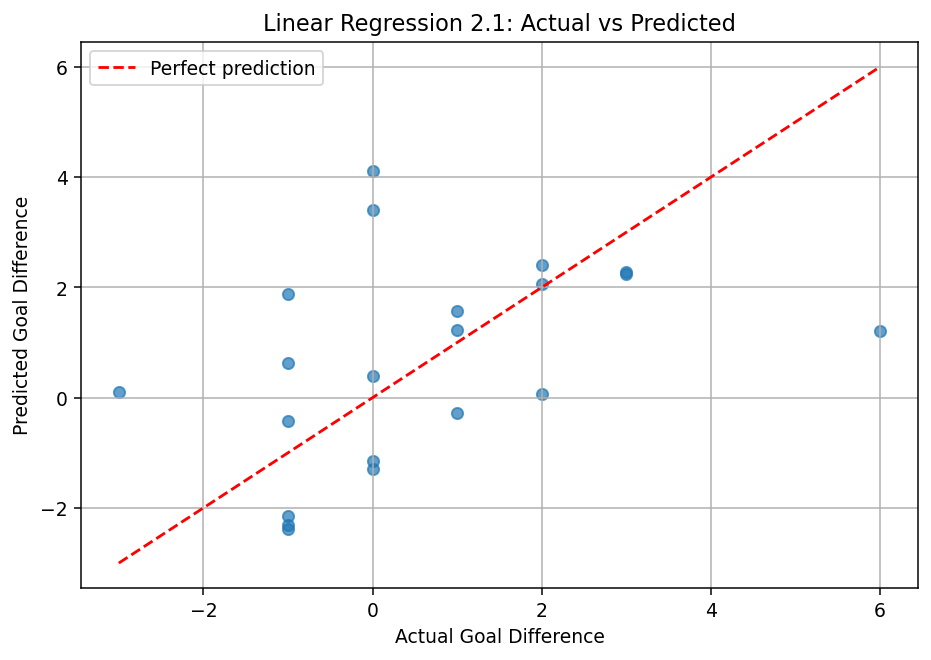

In [17]:
import matplotlib.pyplot as plt

# Linear Regression 2.1 graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--",
         label="Perfect prediction")

plt.xlabel("Actual Goal Difference")
plt.ylabel("Predicted Goal Difference")
plt.title("Linear Regression 2.1: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("analysis_outputs/Regression_2_1_Graph.png", dpi=300)
plt.show()


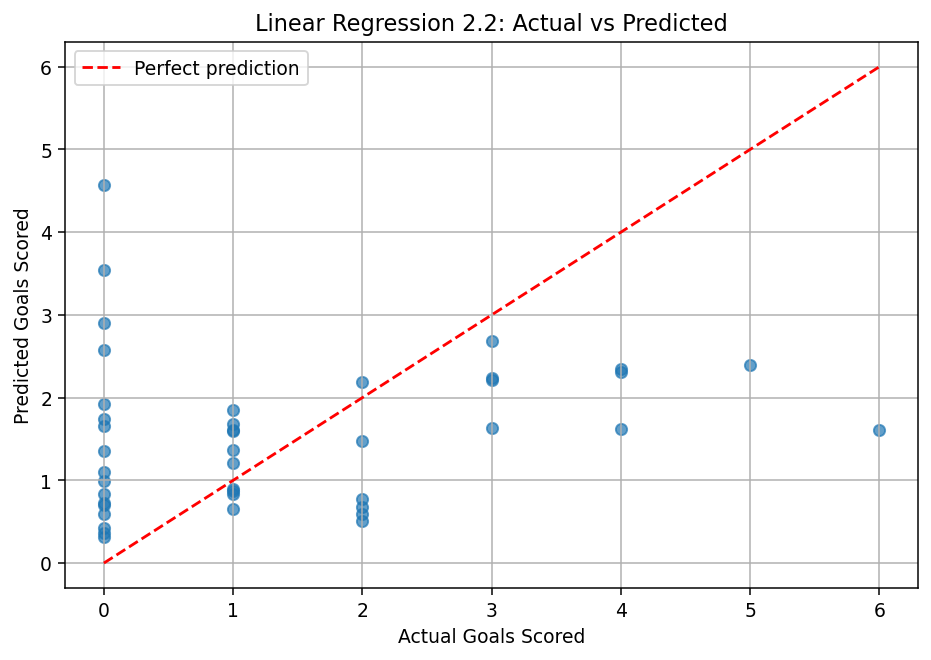

In [18]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test22, y_pred22, alpha=0.7)

limits = [
    min(y_test22.min(), y_pred22.min()),
    max(y_test22.max(), y_pred22.max())
]

plt.plot(limits, limits, "r--",
         label="Perfect prediction")

plt.xlabel("Actual Goals Scored")
plt.ylabel("Predicted Goals Scored")
plt.title("Linear Regression 2.2: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("analysis_outputs/Regression_2_2_Graph.png", dpi=300)
plt.show()


## Original fitted coefficients

A coefficient describes a conditional association while the other included predictors are held fixed.


In [19]:
import pandas as pd

coefficients22 = pd.DataFrame({
    "Variable": x_columns_22,
    "Coefficient": model22.coef_
})

print("Linear Regression 2.2 Coefficients:")
display(coefficients22.round(4))

print("Intercept:", round(model22.intercept_, 4))


Linear Regression 2.2 Coefficients:
Intercept: -6.7278


,Variable,Coefficient
0,team_fifa_rank,0.0051
1,team_elo,0.0038
2,team_prev_avg_goals_scored,-0.3704
3,opponent_prev_avg_goals_conceded,0.4407
4,team_prev_avg_shots_on_target,0.0684
5,team_prev_avg_possession,0.0216
6,opponent_prev_avg_saves,-0.0179
7,is_knockout,-0.3586


In [20]:
# Linear Regression 2.1 coefficients

coefficients21 = pd.DataFrame({
    "Variable": x_columns,
    "Coefficient": model21.coef_
})

print("Linear Regression 2.1 Coefficients:")
display(coefficients21.round(4))

print("Intercept:", round(model21.intercept_, 4))


Linear Regression 2.1 Coefficients:
Intercept: 0.0728


,Variable,Coefficient
0,ranking_diff,0.0073
1,elo_diff,0.0033
2,squad_value_diff,0.0007
3,squad_age_diff,0.0595
4,rest_days_diff,-0.2820
5,previous_goals_scored_diff,-0.2613
6,previous_goals_conceded_diff,-0.3597
7,host_advantage,0.7028


In [21]:
# Check tournament dates and match status

print("First match date:", matches["date"].min())
print("Last match date:", matches["date"].max())

print("\nMatch status:")
print(matches["status"].value_counts())

print("\nCheck first five matches:")
display(matches[
    ["date", "home_team_name", "away_team_name",
     "home_score", "away_score"]
].head())


First match date: 2026-06-11
Last match date: 2026-07-19

Match status:
status
Completed    104
Name: count, dtype: int64

Check first five matches:


,date,home_team_name,away_team_name,home_score,away_score
0,2026-06-11,Mexico,South Africa,2,0
1,2026-06-11,South Korea,Czechia,2,1
2,2026-06-12,Canada,Bosnia and Herzegovina,1,1
3,2026-06-12,USA,Paraguay,4,1
4,2026-06-13,Qatar,Switzerland,1,1


## Basic cross-validation

Add five-fold validation on the training partition only. Task 2.2 uses GroupKFold by match ID. These checks assess the same OLS models; no new model or predictor is selected.


In [22]:
# Basic five-fold cross-validation using ONLY the original training rows.
from sklearn.model_selection import KFold, GroupKFold, cross_validate

scoring = {"mae": "neg_mean_absolute_error",
           "rmse": "neg_root_mean_squared_error", "r2": "r2"}

folds21 = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X_train))
training_match_ids22 = lr22.iloc[train_idx]["match_id"].reset_index(drop=True)
folds22 = list(GroupKFold(n_splits=5).split(
    X_train22, y_train22, groups=training_match_ids22))
for train_fold, validation_fold in folds22:
    assert set(training_match_ids22.iloc[train_fold]).isdisjoint(
        training_match_ids22.iloc[validation_fold])

cv21 = cross_validate(LinearRegression(), X_train, y_train,
                     cv=folds21, scoring=scoring)
cv22 = cross_validate(LinearRegression(), X_train22, y_train22,
                     cv=folds22, scoring=scoring)
cv_rows = []
for task, scores, folds in [("2.1", cv21, folds21), ("2.2", cv22, folds22)]:
    for fold, (training_rows, validation_rows) in enumerate(folds, 1):
        cv_rows.append({"task": task, "fold": fold,
                        "training_rows": len(training_rows),
                        "validation_rows": len(validation_rows),
                        "mae": -scores["test_mae"][fold-1],
                        "rmse": -scores["test_rmse"][fold-1],
                        "r2": scores["test_r2"][fold-1]})
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("task")[["mae", "rmse", "r2"]].mean()
cv_results.to_csv("analysis_outputs/cv_results.csv", index=False)
print("Five-fold training-only validation: arithmetic mean scores")
display(cv_summary.round(4))
print("Task 2.2 keeps both team rows from a match together in every fold.")



Five-fold training-only validation: arithmetic mean scores
Task 2.2 keeps both team rows from a match together in every fold.


,mae,rmse,r2
task,,,
2.1,1.219,1.5272,0.2171
2.2,0.904,1.2019,0.1092


## Reproduce the report figures

Use the supplied records for descriptive summaries and Pearson correlations. These full-data plots are descriptive, not independent validation or a basis for choosing predictors.


,Goal difference,Team goals
count,104.0000,208.0000
mean,0.4808,1.4808
std,2.0240,1.3934
min,-4.0000,0.0000
25%,-1.0000,0.0000
50%,0.0000,1.0000
75%,2.0000,2.0000
max,6.0000,7.0000


elo_diff                        0.6540
ranking_diff                    0.6068
squad_value_diff                0.5673
host_advantage                  0.1600
previous_goals_scored_diff      0.1437
rest_days_diff                 -0.0144
squad_age_diff                 -0.0594
previous_goals_conceded_diff   -0.3116

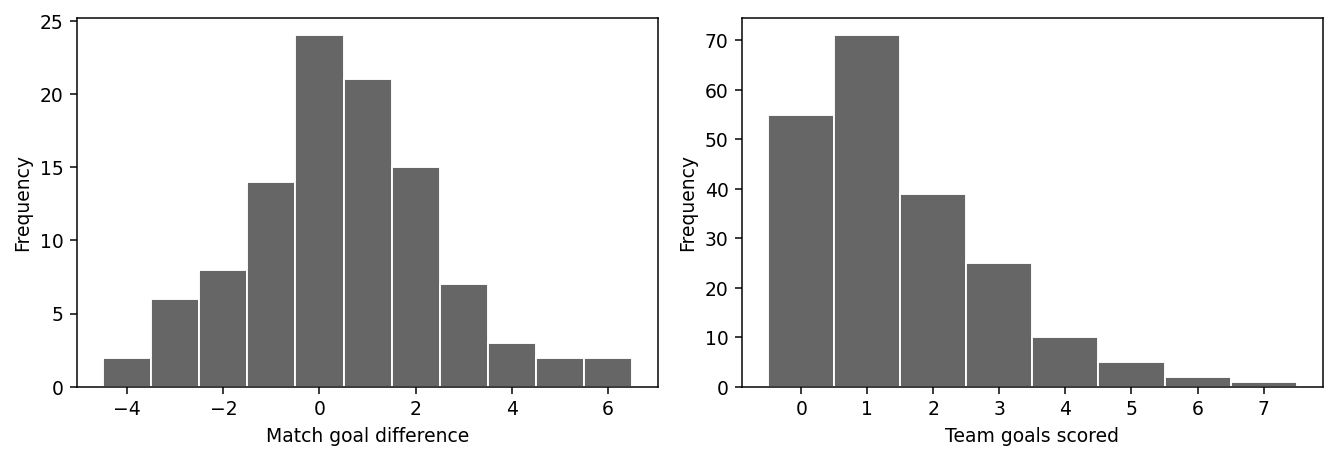

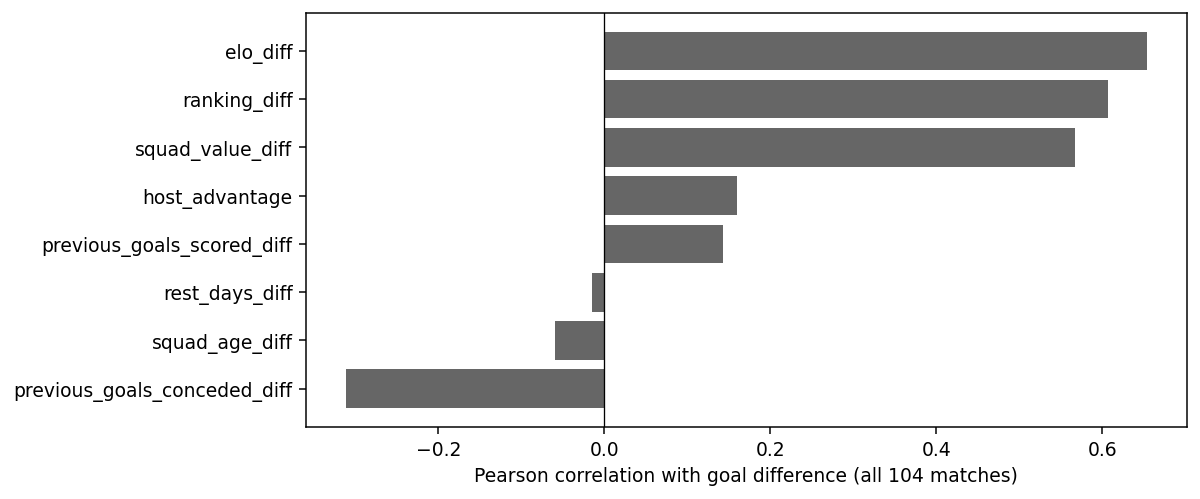

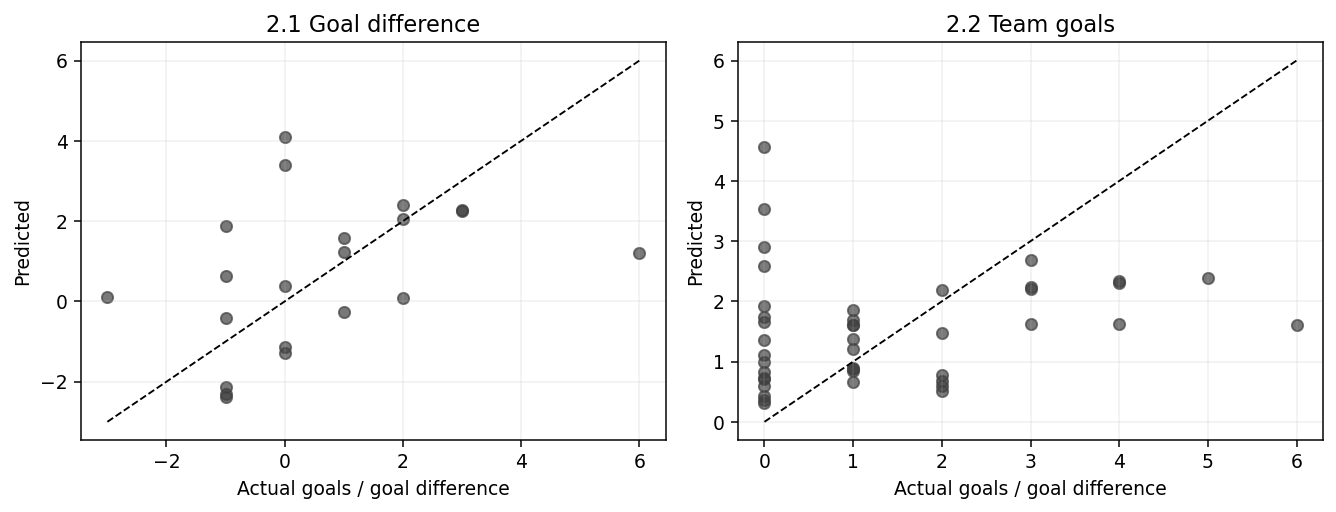

In [23]:
# Reproduce the report's descriptive statistics and figures.
# These describe all supplied records; they do not select predictors or models.
target_stats = pd.DataFrame({
    "Goal difference": lr21["goal_difference"].describe(),
    "Team goals": lr22["goals_scored"].describe()})
display(target_stats.round(4))
correlations21 = lr21[x_columns + ["goal_difference"]].corr()[
    "goal_difference"].drop("goal_difference").sort_values(ascending=False)
display(correlations21.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(lr21["goal_difference"], bins=np.arange(-4.5, 7.5, 1),
             color="0.4", edgecolor="white")
axes[0].set(xlabel="Match goal difference", ylabel="Frequency")
axes[1].hist(lr22["goals_scored"], bins=np.arange(-0.5, 8.5, 1),
             color="0.4", edgecolor="white")
axes[1].set(xlabel="Team goals scored", ylabel="Frequency")
fig.tight_layout()
fig.savefig("analysis_outputs/Report_Target_Distributions.png", dpi=220)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(correlations21.index, correlations21.values, color="0.4")
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlabel("Pearson correlation with goal difference (all 104 matches)")
fig.tight_layout()
fig.savefig("analysis_outputs/Report_Goal_Difference_Correlations.png", dpi=220)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, actual, predicted, title in [
    (axes[0], y_test, y_pred, "2.1 Goal difference"),
    (axes[1], y_test22, y_pred22, "2.2 Team goals")]:
    ax.scatter(actual, predicted, color="0.25", alpha=0.7)
    limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
    ax.plot(limits, limits, "k--", linewidth=1)
    ax.set(xlabel="Actual goals / goal difference", ylabel="Predicted", title=title)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("analysis_outputs/Report_Test_Predictions.png", dpi=220)
plt.show()



## Compare the models

Compare a training-mean benchmark, original OLS and scaled Ridge on identical folds. Freeze the Ridge choice using training CV before evaluating the additional test predictions.


In [24]:
# Compare models on the SAME original training folds and eight inputs.
# The mean is a benchmark; both required original OLS models remain intact.
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import json

ridge_alphas = [1.0, 10.0, 100.0]
candidate_specs = [("Mean", None, DummyRegressor(strategy="mean")),
                   ("OLS", None, LinearRegression())]
candidate_specs += [("Ridge", alpha,
                     make_pipeline(StandardScaler(), Ridge(alpha=alpha)))
                    for alpha in ridge_alphas]
comparison_training = [("2.1", X_train, y_train, folds21),
                       ("2.2", X_train22, y_train22, folds22)]
comparison_fold_rows, comparison_cv_rows = [], []
for task, train_x, train_y, folds in comparison_training:
    for name, alpha, estimator in candidate_specs:
        scores = cross_validate(estimator, train_x, train_y, cv=folds,
                                scoring=scoring, error_score="raise")
        for i, (fit_rows, valid_rows) in enumerate(folds):
            comparison_fold_rows.append({
                "task": task, "model": name, "alpha": alpha, "fold": i + 1,
                "training_rows": len(fit_rows), "validation_rows": len(valid_rows),
                "mae": -scores["test_mae"][i],
                "rmse": -scores["test_rmse"][i], "r2": scores["test_r2"][i]})
        comparison_cv_rows.append({
            "task": task, "model": name, "alpha": alpha,
            "cv_mae": -scores["test_mae"].mean(),
            "cv_rmse": -scores["test_rmse"].mean(),
            "cv_r2": scores["test_r2"].mean(),
            "cv_rmse_sd": scores["test_rmse"].std(ddof=1)})
comparison_folds = pd.DataFrame(comparison_fold_rows)
comparison_cv = pd.DataFrame(comparison_cv_rows)
selected_ridge_alphas = {}
for task in ["2.1", "2.2"]:
    choices = comparison_cv[(comparison_cv["task"] == task) &
                            (comparison_cv["model"] == "Ridge")]
    best = choices.sort_values(["cv_rmse", "alpha"]).iloc[0]
    selected_ridge_alphas[task] = float(best["alpha"])
    original = comparison_cv[(comparison_cv["task"] == task) &
                             (comparison_cv["model"] == "OLS")].iloc[0]
    assert np.allclose(original[["cv_mae", "cv_rmse", "cv_r2"]].astype(float),
                       cv_summary.loc[task, ["mae", "rmse", "r2"]])
comparison_folds.to_csv("analysis_outputs/comparison_cv_folds.csv", index=False)
comparison_cv.to_csv("analysis_outputs/comparison_cv_summary.csv", index=False)
# Freeze the training-only choice BEFORE evaluating the additional test predictions.
selection = {"ridge_alphas_tried": ridge_alphas,
             "selection_rule": "Lowest mean five-fold training CV RMSE",
             "selected_ridge_alphas": selected_ridge_alphas,
             "scaling": "StandardScaler fitted inside each training fold",
             "cv_interpretation": "Selection scores, not independent post-selection estimates",
             "test_history": "Original test outcomes were inspected in earlier drafts"}
Path("analysis_outputs/comparison_selection.json").write_text(
    json.dumps(selection, indent=2))

comparison_rows, comparison_predictions = [], {}
for task, train_x, train_y, test_x, test_y, original_model in [
    ("2.1", X_train, y_train, X_test, y_test, model21),
    ("2.2", X_train22, y_train22, X_test22, y_test22, model22)]:
    assert train_x.shape[1] == test_x.shape[1] == 8
    alpha = selected_ridge_alphas[task]
    estimators = [("Mean", None, DummyRegressor(strategy="mean")),
                  ("OLS", None, original_model),
                  ("Ridge", alpha, make_pipeline(StandardScaler(), Ridge(alpha=alpha)))]
    for name, penalty, estimator in estimators:
        if name != "OLS": estimator.fit(train_x, train_y)
        prediction = estimator.predict(test_x)
        comparison_predictions[(task, name)] = np.asarray(prediction)
        valid = comparison_cv[(comparison_cv["task"] == task) &
                              (comparison_cv["model"] == name)]
        if name == "Ridge": valid = valid[valid["alpha"] == penalty]
        valid = valid.iloc[0]
        comparison_rows.append({
            "task": task, "model": name, "alpha": penalty,
            "test_r2": r2_score(test_y, prediction),
            "test_mae": mean_absolute_error(test_y, prediction),
            "test_rmse": np.sqrt(mean_squared_error(test_y, prediction)),
            "cv_r2": valid["cv_r2"], "cv_mae": valid["cv_mae"],
            "cv_rmse": valid["cv_rmse"]})
model_comparison = pd.DataFrame(comparison_rows)
model_comparison.to_csv("analysis_outputs/model_comparison.csv", index=False)
print("Training CV selects Ridge alpha:", selected_ridge_alphas)
display(model_comparison.round(4))
print("Ridge CV values were used for selection; they are not fresh independent estimates.")
print("The original test outcomes had been examined in earlier drafts.")


Training CV selects Ridge alpha: {'2.1': 10.0, '2.2': 10.0}
Ridge CV values were used for selection; they are not fresh independent estimates.
The original test outcomes had been examined in earlier drafts.


,task,model,alpha,test_r2,test_mae,test_rmse,cv_r2,cv_mae,cv_rmse
0,2.1,Mean,NaN,-0.0035,1.4940,1.9200,-0.2022,1.6297,2.0245
1,2.1,OLS,NaN,-0.1316,1.5750,2.0388,0.2171,1.2190,1.5272
2,2.1,Ridge,10.0,-0.0989,1.5436,2.0092,0.2571,1.2026,1.5001
3,2.2,Mean,NaN,-0.0099,1.3130,1.5634,-0.0536,1.0720,1.3167
4,2.2,OLS,NaN,-0.1316,1.2498,1.6548,0.1092,0.9040,1.2019
5,2.2,Ridge,10.0,-0.0762,1.2249,1.6138,0.1365,0.9024,1.1890


## Investigate prediction errors

Inspect residuals for original OLS and the selected Ridge comparison. These diagnostics describe the reused test partitions; no further tuning follows.


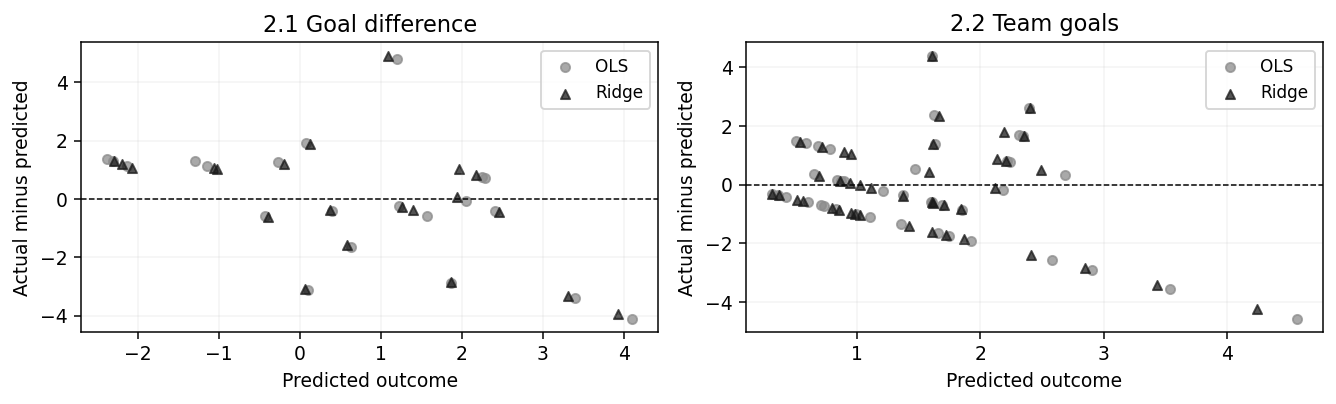

,task,model,mean_residual,mae,rmse,max_absolute_error,negative_predictions
0,2.1,OLS,-0.0763,1.5750,2.0388,4.7945,7
1,2.1,Ridge,-0.0629,1.5436,2.0092,4.9134,7
2,2.2,OLS,-0.1706,1.2498,1.6548,4.5677,0
3,2.2,Ridge,-0.1705,1.2249,1.6138,4.3893,0


In [25]:
# Residual = recorded outcome minus prediction; positive means underprediction.
diagnostic_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.1))
for task, actual, ax, title in [("2.1", np.asarray(y_test), axes[0], "2.1 Goal difference"),
                                ("2.2", np.asarray(y_test22), axes[1], "2.2 Team goals")]:
    for name, colour, marker in [("OLS", "0.55", "o"), ("Ridge", "0.1", "^")]:
        predicted = comparison_predictions[(task, name)]
        residual = actual - predicted
        diagnostic_rows.append({"task": task, "model": name,
            "mean_residual": residual.mean(), "mae": np.abs(residual).mean(),
            "rmse": np.sqrt(np.mean(residual ** 2)),
            "max_absolute_error": np.abs(residual).max(),
            "negative_predictions": int((predicted < 0).sum())})
        ax.scatter(predicted, residual, color=colour, marker=marker,
                   alpha=0.75, s=24, label=name)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel="Predicted outcome", ylabel="Actual minus predicted", title=title)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig("analysis_outputs/Report_Test_Residuals.png", dpi=220)
plt.show()
diagnostic_summary = pd.DataFrame(diagnostic_rows)
diagnostic_summary.to_csv("analysis_outputs/diagnostic_summary.csv", index=False)
display(diagnostic_summary.round(4))
